Get the data


In [2]:
# %pip install yfinance pandas numpy matplotlib seaborn

import numpy as np
import pandas as pd
import yfinance as yf
import warnings

warnings.filterwarnings("ignore")
pd.options.display.float_format = '{:.4%}'.format

# Date range
start = '2022-01-01'
end = '2025-05-30'

# Tickers of assets
assets = ['NTC.JO', 'NPN.JO', 'ITE.JO', 'GLN.JO', 'MPT.JO', 'REM.JO', 'ANH.JO',
          'MRP.JO', 'CMH.JO', 'SUI.JO', 'NED.JO', 'FSR.JO', 'SOL.JO', 'AFE.JO', 'SHP.JO',
          'BVT.JO', 'RNI.JO', 'LHC.JO', 'AVI.JO', 'AIP.JO', 'MTN.JO', 'BLU.JO', 'SSW.JO', 'WHL.JO']
assets.sort()

# Downloading data
data = yf.download(assets, start = start, end = end, auto_adjust=False)
data = data.loc[:,('Adj Close', slice(None))]
data.columns = assets

[*********************100%***********************]  24 of 24 completed


In [3]:
# calculate returns 
y = data[assets].pct_change().dropna()
# display(y.head())

let's estimate the mean variance portfolios

In [4]:
# %pip install riskfolio-lib

import riskfolio as rp

# Create a portfolio object
port = rp.Portfolio(returns=y)

#calculate optimum portfolio
#select method and estimate input parameters

method_mu = 'hist' #method to estimate expected returns by using historical data
method_cov = 'hist' #method to estimate expected covariance matrix using //

port.assets_stats(method_mu=method_mu, method_cov=method_cov)

# estimate optimal portoflio

model = 'Classic' # classic is historical, could be blacklitterman or factor model
rm = 'CVaR' #risk measure used, could be 'MV', 'MAD', 'CVaR', 'WR' or 'MDD'
obj = 'MinRisk' #objective function, could be 'Sharpe', 'Utility', 'MinRisk', 'MinVariance', 'MaxRet'
hist = True #true if using historical scenarios for risk measures, that depend on scenarios or false if using forecasted data
rf = 0 # risk free rate
l = 0 #risk aversion factor, not used now - use when the objective fuction is 'Utility'

w = port.optimization(model=model, rm=rm, obj=obj, rf=rf, l=l, hist=hist)

display(w.T)

,AFE.JO,AIP.JO,ANH.JO,AVI.JO,BLU.JO,BVT.JO,CMH.JO,FSR.JO,GLN.JO,ITE.JO,...,NED.JO,NPN.JO,NTC.JO,REM.JO,RNI.JO,SHP.JO,SOL.JO,SSW.JO,SUI.JO,WHL.JO
weights,0.0000%,11.4729%,1.5654%,14.0122%,5.0381%,2.7853%,0.0000%,0.0000%,3.4475%,11.5871%,...,0.0000%,3.8190%,15.3239%,0.0000%,13.8588%,1.8814%,0.0000%,0.0000%,0.0000%,3.6299%


Let's plot our optimised compositions

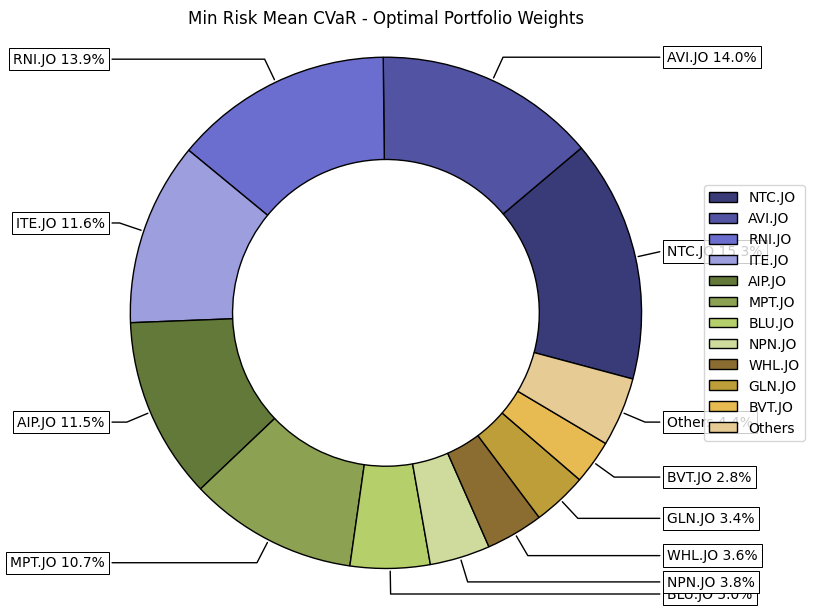

In [5]:
# plot optimal portfolio weights

ax = rp.plot_pie(w, title='Min Risk Mean CVaR - Optimal Portfolio Weights', others=0.05, nrow = 25, cmap = "tab20b" ,height=6, width=8, ax = None)

In [6]:
# number of assets in the portfolio
assets = np.sum(np.where(np.round(w,4) > 0, 1, 0)).item()

# number of effective assets in this portfolio
effective_assets = 1/np.sum(w ** 2).item()

print('Nuber of assets:', assets)
print("Number of effective assets:", effective_assets)

Nuber of assets: 14
Number of effective assets: 9.239385885485287


# Calculate the portfolio including a constraint on the max number of assets

a constraint like this can help us limit the max number of assets - helpful for small investors that can't afford to buy too many assets

In [ ]:
# first we need a solver and set it that it support mixed integer programming

port.solvers = ['MOSEK']

# then we need to set the cardinality constraint (max number of assets)

port.card =  8

w = port.optimization(model=model, rm=rm, obj=obj, rf=rf, l=l, hist=hist)
display(w.T)

The problem doesn't have a solution with actual input parameters


AttributeError: 'NoneType' object has no attribute 'T'